# Day 8: Model Explainability and Feature Importance

## Objective

To identify the most influential features used by the tuned Random Forest model for predicting hotel booking cancellations.

## Tasks
- Load the trained Random Forest model.
- Analyze feature importance.
- Visualize the most important features.
- Interpret the results in the context of hotel booking cancellations.

#### Load the Tuned Random Forest Model

In [2]:

# Import joblib to load the saved model
import joblib

# Load our tuned Random Forest pipeline
model = joblib.load("../models/tuned_random_forest.pkl")
print(model)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                min_frequency=100),
                                                  ['hotel',
                                                   'arrival_date_month', 'meal',
                                                   'country', 'market_segment',
                                                   'distribution_channel',
                                                   'reserved_room_type',
                                                   'deposit_type',
                                                   'customer_type']),
                                                 ('num', StandardScaler(),
                                                  ['lead_time',
                                                   'arrival_date_year',
                   

Our saved pipeline contains two important parts:
1. Preprocessing: Converts categorical features into numerical features and scales numerical columns.
2. Random Forest: Uses the processed features to predict whether a booking will be canceled.
We don't need to train the model again

#### Extract Feature Importance

In [3]:

# Extract the trained Random Forest from the pipeline
rf_model = model.named_steps["model"]

# Extract the fitted preprocessing step
preprocessor = model.named_steps["preprocessing"]

# Get feature names after one-hot encoding
feature_names = preprocessor.get_feature_names_out()

# Get importance scores from Random Forest
importances = rf_model.feature_importances_

# Check the number of features and importance scores
print("Total Features:", len(feature_names))
print("Total Importance Scores:", len(importances))


Total Features: 103
Total Importance Scores: 103


#### Identify the Top 15 Important Features

finding which features our Random Forest relies on most when predicting hotel booking cancellations.

In [4]:

# Import pandas
import pandas as pd

# Create a DataFrame containing feature names and importance scores
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort features from highest to lowest importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 important features
print(feature_importance_df.head(15))


                             Feature  Importance
79      cat__deposit_type_Non Refund    0.112403
78      cat__deposit_type_No Deposit    0.102801
85                    num__lead_time    0.100319
48                  cat__country_PRT    0.093285
99    num__total_of_special_requests    0.066425
97                          num__adr    0.045803
95       num__previous_cancellations    0.038572
62     cat__market_segment_Online TA    0.031620
98  num__required_car_parking_spaces    0.027933
87     num__arrival_date_week_number    0.026384
88    num__arrival_date_day_of_month    0.025904
90         num__stays_in_week_nights    0.022864
60        cat__market_segment_Groups    0.022194
86            num__arrival_date_year    0.021205
83      cat__customer_type_Transient    0.020113


1. Deposit type: Both Non Refund and No Deposit rank highly. This suggests the model relies heavily on deposit information when making predictions.

2. Lead time: The number of days between booking and arrival is an important predictor. We also observed during EDA that longer lead times were associated with more cancellations.

3. Country (PRT): Whether the booking belongs to the Portugal category is influential in this dataset. However, this doesn't mean Portuguese guests inherently cancel more often.

4. Special requests: The number of requests made by guests is another important feature. During EDA, we observed that bookings with more special requests tended to have lower cancellation rates.

Important: Feature importance tells us how strongly the model uses a feature, not whether that feature increases or decreases cancellation probability. Also, one-hot encoding splits categorical variables into separate columns, so these are individual transformed-feature scores rather than overall importance for each original variable.

#### Visualize the Top 15 Features

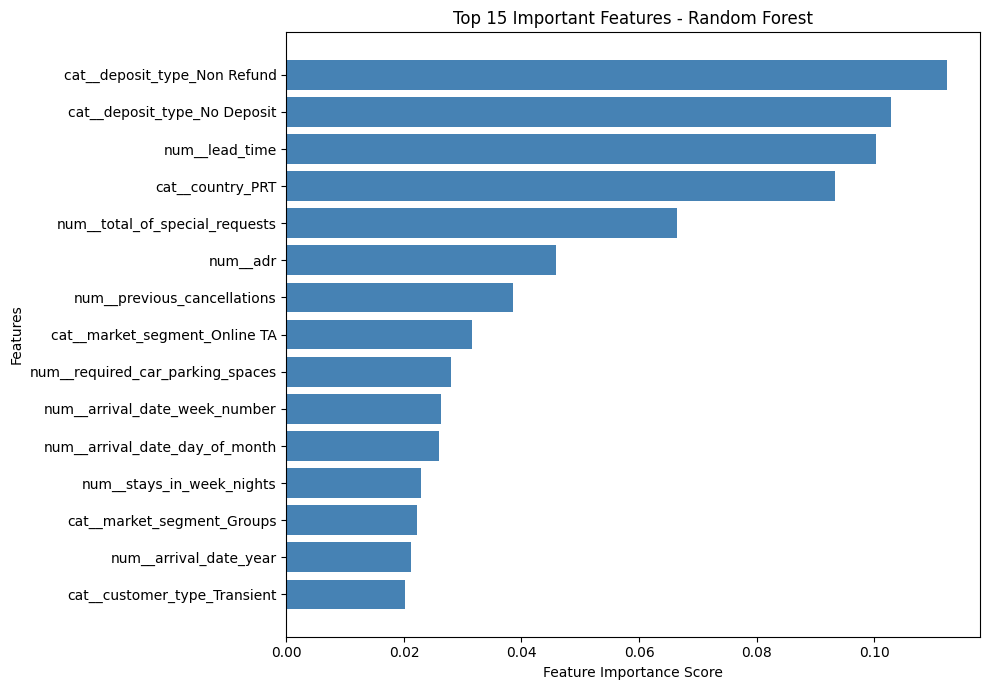

In [8]:

import matplotlib.pyplot as plt

# Select the top 15 important features
top_15 = feature_importance_df.head(15)

# Create a horizontal bar chart
plt.figure(figsize=(10, 7))

plt.barh(
    top_15["Feature"],
    top_15["Importance"],
    color="steelblue"
)

# Display the most important feature at the top
plt.gca().invert_yaxis() #gce mean get current axis it selscts the axes of the grph, reverts the y axis

# Add labels and title
plt.xlabel("Feature Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Random Forest")

plt.tight_layout()
# Save the feature importance graph
plt.savefig("../images/feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


#### group Feature Importance by Original Feature
we used One-Hot Encoding during preprocessing

For example, deposit_type became separate features such as:
- cat__deposit_type_Non Refund
- cat__deposit_type_No Deposit
- cat__deposit_type_Refundable
Currently, our graph displays these separately. But we also want to understand the overall importance of each original feature.

Let's combine the importance scores belonging to the same original column.

In [9]:

# Get the original input feature names
original_features = model.feature_names_in_

# Match each transformed feature to its original column
def get_original_feature(name):
    if name.startswith("num__"):
        return name.replace("num__", "", 1)

    for col in original_features:
        if name.startswith("cat__" + col + "_"):
            return col

    return name

# Add original feature names to our importance table
feature_importance_df["Original Feature"] = (
    feature_importance_df["Feature"].apply(get_original_feature)
)

# Combine importance scores for the same original feature
grouped_importance = (
    feature_importance_df.groupby("Original Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 original features
print(grouped_importance.head(10))


Original Feature
deposit_type                   0.215389
country                        0.134197
lead_time                      0.100319
market_segment                 0.083292
total_of_special_requests      0.066425
adr                            0.045803
customer_type                  0.041335
previous_cancellations         0.038572
arrival_date_month             0.030272
required_car_parking_spaces    0.027933
Name: Importance, dtype: float64


Suppose deposit_type has three encoded columns with importance scores of 0.11, 0.10, and 0.01.

Its combined importance would be:

\(0.11 + 0.10 + 0.01 = 0.22\)

This gives us a clearer overview of how much the model relies on the original booking variables rather than individual encoded categories.

One note: this is a sum of Random Forest impurity-based importance scores. It is useful for summarizing our model, but it is not a causal measure and can favor features with many categories.

#### Visualize Original Feature Importance



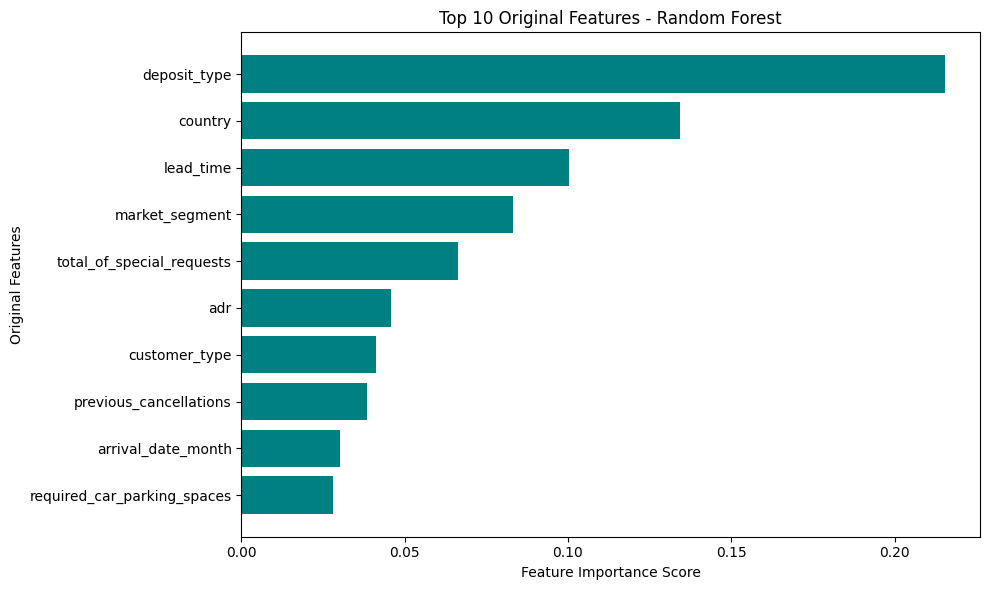

In [10]:

# Select the top 10 original features
top_10_original = grouped_importance.head(10)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(
    top_10_original.index,
    top_10_original.values,
    color="teal"
)

# Show the most important feature at the top
plt.gca().invert_yaxis()

# Add title and labels
plt.title("Top 10 Original Features - Random Forest")
plt.xlabel("Feature Importance Score")
plt.ylabel("Original Features")

plt.tight_layout()

# Save the graph for our presentation
plt.savefig("../images/original_feature_importance.png",
            dpi=300, bbox_inches="tight")

plt.show()


#### Saving the feature importance reuslts as CSV

In [12]:

# Convert grouped feature importance into a DataFrame
original_importance_df = grouped_importance.reset_index() #CONVERTS GROUPED SERIES INTO DF

# Rename the columns
original_importance_df.columns = ["Feature", "Importance"]

# Save the results as a CSV file
original_importance_df.to_csv(
    "../data/feature_importance.csv",
    index=False
)

# Display the first 10 rows
print(original_importance_df.head(10))

print("Feature importance results saved successfully!")


                       Feature  Importance
0                 deposit_type    0.215389
1                      country    0.134197
2                    lead_time    0.100319
3               market_segment    0.083292
4    total_of_special_requests    0.066425
5                          adr    0.045803
6                customer_type    0.041335
7       previous_cancellations    0.038572
8           arrival_date_month    0.030272
9  required_car_parking_spaces    0.027933
Feature importance results saved successfully!


## Feature Importance Analysis — Findings

The tuned Random Forest model was analyzed to identify the most influential features in hotel booking cancellation prediction.

### Key Findings

1. **Deposit Type (21.54%)** was the most influential feature, suggesting that deposit policies play an important role in the model's predictions.
2. **Country (13.42%)** was the second most influential feature, indicating that booking origin information contributes to the model's decisions.
3. **Lead Time (10.03%)** was another important predictor. Earlier EDA showed that bookings made further in advance tended to have higher cancellation rates.
4. **Market Segment (8.33%)** influenced predictions, indicating differences in booking patterns across market segments.
5. **Total Special Requests (6.64%)** was also important. Earlier EDA suggested that bookings with more special requests were associated with lower cancellation rates.

### Conclusion

Deposit type, country, lead time, market segment, and special requests were the most influential original features in the tuned Random Forest model.

The importance scores were calculated using impurity-based feature importance. These scores explain how the model uses the features, but they do not establish causal relationships. Features with many encoded categories may also receive higher combined importance scores.